## HuggingFace Pipeline

### What is a Hugging Face Pipeline?

The `pipeline()` is the easiest and most versatile way to use a Hugging Face model for inference. It abstracts away the complex code of preprocessing (tokenizing text, resizing images, or converting audio), passing data through the model, and postprocessing the outputs into user-friendly formats.

Key features of pipelines include:
* **Ease of Use:** You can initialize a state-of-the-art model with a single line of code.
* **Task-based API:** You can instantiate a pipeline by simply specifying the name of the task (e.g., `"text-classification"`, `"image-classification"`, `"text-to-speech"`).
* **Flexibility:** It automatically handles downloading correct models, tokenizers, and feature extractors from the Hugging Face Hub under the hood.

Source:

https://huggingface.co/docs/transformers/main_classes/pipelines$0

In [1]:
# Call pipeline from HuggingFace
from transformers import pipeline
from transformers.pipelines import SUPPORTED_TASKS

# Show all available task identifiers
for task_name in sorted(SUPPORTED_TASKS.keys()):
    print(task_name)

any-to-any
audio-classification
automatic-speech-recognition
depth-estimation
document-question-answering
feature-extraction
fill-mask
image-classification
image-feature-extraction
image-segmentation
image-text-to-text
keypoint-matching
mask-generation
object-detection
table-question-answering
text-classification
text-generation
text-to-audio
token-classification
video-classification
zero-shot-audio-classification
zero-shot-classification
zero-shot-image-classification
zero-shot-object-detection


### 1. Text Classification

Text Classification is a fundamental Natural Language Processing (NLP) task that assigns a set of predefined categories (or labels) to open-ended text. Common applications include sentiment analysis (classifying text as positive, negative, or neutral), spam detection, and topic tagging.

In [2]:
scrambled_reviews = [
    "An absolute masterpiece of modern cinema.",
    "I was completely blown away by how incredible this was.",
    "A breathtaking journey with a truly heartwarming conclusion.",
    "The acting was top-tier, especially from the lead role.",
    "A beautiful, poignant story that had me in tears.",
    "Easily one of the best films of the decade.",
    "The direction was flawless, creating a stunning atmosphere.",
    "An incredibly fun ride from start to finish.",
    "A brilliant blend of humor, drama, and action.",
    "I cannot recommend this movie highly enough!",
    "Every single frame of this movie is a work of art.",
    "A rare gem that exceeded all my lofty expectations.",
    "A highly entertaining spectacle that leaves you wanting more.",
    "The cinematography was simply out of this world.",
    "A clever, witty script that keeps you fully engaged.",
    "A magical experience that captured my imagination completely.",
    "The chemistry between the main characters was electric.",
    "A powerful story told with absolute grace and elegance.",
    "I was on the edge of my seat the entire time.",
    "An instant classic that will be remembered for years.",
    "A wonderfully uplifting and inspiring cinematic treat.",
    "The sound design and score were absolutely magnificent.",
    "A captivating narrative that is both smart and emotional.",
    "I loved every single second of this fantastic film.",
    "A phenomenal achievement in filmmaking.",
    "A masterful execution of a brilliant premise.",
    "The emotional depth of this movie is unparalleled.",
    "An incredibly charming and delightful experience.",
    "A bold and original film that deserves all the praise.",
    "A heartwarming story that resonates on every level.",
    "A stellar cast delivering career-defining performances.",
    "An unforgettable cinematic experience that stays with you.",
    "A triumph of creativity and storytelling.",
    "It is a beautiful love letter to the art of cinema.",
    "The pacing was perfect, never letting go of your attention.",
    "A profoundly moving and thought-provoking masterpiece.",
    "The climax was incredibly satisfying and well-executed.",
    "A dazzling display of talent both in front of and behind the camera.",
    "A brilliantly crafted film with endless rewatch value.",
    "I was utterly mesmerized by the sheer beauty of it.",
    "An exceptional piece of work that hits all the right notes.",
    "A refreshing and highly original take on a familiar theme.",
    "A sheer delight from the opening scene to the credits.",
    "It handles complex themes with incredible maturity and sensitivity.",
    "The writing is exceptionally sharp and full of wit.",
    "An absolute joy to watch, a film that makes you feel good.",
    "A gripping drama with immense emotional weight.",
    "The attention to detail in this film is extraordinary.",
    "A visually spectacular and highly engaging adventure.",
    "It completely redefines what a blockbuster can be.",
    "A beautiful exploration of human relationships and love.",
    "The narrative kept me guessing, in the best way possible.",
    "A stunningly realized world that feels alive and deep.",
    "It is a cinematic triumph that deserves a standing ovation.",
    "An exquisitely crafted story with deep emotional resonance.",
    "A thrilling ride that is as smart as it is exciting.",
    "The performance by the supporting cast was absolutely stellar.",
    "A heartwarming and deeply satisfying cinematic journey.",
    "It will make you laugh, cry, and think.",
    "A perfectly paced movie with no wasted scenes.",
    "An absolute must-watch for anyone who loves great stories.",
    "It is a work of pure genius that demands to be seen.",
    "The film is an absolute joy from beginning to end.",
    "An incredibly powerful and beautifully realized narrative.",
    "The visual effects are cutting-edge and highly impressive.",
    "A masterpiece of suspense and dramatic tension.",
    "It is a beautiful, life-affirming piece of cinema.",
    "A spectacular accomplishment that left me speechless.",
    "The screenplay is brilliantly written and perfectly delivered.",
    "A rich, rewarding film that gets better with every viewing.",
    "An absolute disaster from the very first minute.",
    "I completely regretted wasting my afternoon on this.",
    "A tedious, boring film that felt like it would never end.",
    "The acting was incredibly wooden and completely unconvincing.",
    "A messy, incoherent plot that made absolutely no sense.",
    "Easily one of the worst movies I have ever seen.",
    "The direction was non-existent, leaving the film feeling lost.",
    "An incredibly annoying and frustrating viewing experience.",
    "A cheap, lazy attempt to cash in on a popular franchise.",
    "I cannot warn you away from this movie strongly enough.",
    "Every single scene felt like a chore to get through.",
    "A major disappointment that failed in every aspect.",
    "A highly repetitive and dull film with zero redeeming qualities.",
    "The cinematography was ugly and poorly lit throughout.",
    "A stupid, clichéd script that insulted the audience.",
    "A painful experience that lacked any sense of charm.",
    "The chemistry between the leads was absolutely non-existent.",
    "A weak story told with zero enthusiasm or skill.",
    "I was checking my watch every five minutes.",
    "An instant flop that will be quickly forgotten.",
    "A thoroughly depressing and uninspiring waste of time.",
    "The sound design was grating and the score was obnoxious.",
    "A convoluted mess of a narrative that tries to be smart.",
    "I hated nearly every single minute of this terrible film.",
    "A complete failure in both pacing and character development.",
    "A lazy execution of a potentially interesting premise.",
    "The emotional beats felt completely unearned and fake.",
    "An incredibly irritating film with obnoxious characters.",
    "A dull and unoriginal script that bored me to tears.",
    "A predictable story that offered absolutely no surprises.",
    "The cast delivered uninspired and lazy performances.",
    "An forgettable mess that leaves a bad taste in your mouth.",
    "A complete waste of money, talent, and resources.",
    "It feels like an amateur student project with a high budget.",
    "The pacing was painfully slow, dragging out simple scenes.",
    "A pretentious and deeply self-indulgent piece of trash.",
    "The ending was incredibly stupid and completely unsatisfying.",
    "A cheap-looking film despite the massive budget it had.",
    "A poorly crafted movie that lacks any logical coherence.",
    "I was utterly bored by the lack of any real stakes.",
    "An awful film that shouldn't have been greenlit.",
    "A ridiculous and highly unbelievable plot.",
    "A frustrating experience that felt completely pointless.",
    "It fails to deliver on any of its promises.",
    "The writing is exceptionally lazy and full of clichés.",
    "An absolute chore to watch, draining all my energy.",
    "A cheap drama with cartoonish and flat characters.",
    "The lack of effort in this film is truly disappointing.",
    "A messy and highly confusing sci-fi disaster.",
    "It completely misses the mark and fails to entertain.",
    "A superficial story that lacks any real heart or depth.",
    "The narrative was completely disjointed and hard to follow.",
    "A hollow world that feels completely fake and lifeless.",
    "It is a cinematic failure that should be avoided.",
    "An agonizingly slow and pointless waste of celloid.",
    "A loud, obnoxious, and utterly mindless experience.",
    "The performance by the lead actor was incredibly painful to watch.",
    "A disappointing sequel that ruins the original.",
    "It will make you roll your eyes in absolute disbelief.",
    "A poorly paced movie filled with useless filler scenes.",
    "An absolute skip for anyone who values their time.",
    "It is a work of pure laziness that offers nothing new.",
    "The film is an absolute headache from beginning to end.",
    "An incredibly weak narrative with zero character growth.",
    "The visual effects are outdated and look incredibly fake.",
    "A complete absence of suspense or dramatic interest.",
    "It is a dull, depressing, and unengaging film.",
    "A spectacular failure that leaves you feeling annoyed.",
    "The screenplay is terribly written and badly executed.",
    "A shallow film that gets worse the more you think about it.",
    "The movie was okay, but it didn't leave much of an impression.",
    "It had a few decent moments, but was mostly average.",
    "The acting was fine, though the plot was predictable.",
    "An average film that is worth a watch if nothing else is on.",
    "It has some good elements, but is balanced by equal flaws.",
    "A fairly standard entry in this particular genre.",
    "It wasn't terrible, but it certainly wasn't great.",
    "A middle-of-the-road film with a few entertaining scenes.",
    "Some parts were interesting, but the pacing was inconsistent.",
    "It delivered exactly what I expected, nothing more, nothing less.",
    "A competent film that doesn't take many creative risks.",
    "The cinematography was nice, but the story was just mediocre.",
    "It kept my attention, but I probably won't watch it again.",
    "A decent popcorn flick that is easy to forget.",
    "It has its ups and downs, making for an average experience.",
    "The cast did a reasonable job with a basic script.",
    "An acceptable way to pass two hours of your time.",
    "Some jokes landed well, while others fell completely flat.",
    "It walks a very safe path without being overly exciting.",
    "A predictable but still somewhat watchable movie.",
    "It has some style, though the substance is a bit lacking.",
    "Not a bad movie, but nothing to write home about either.",
    "The story was passable, but the characters were a bit bland.",
    "It’s a functional piece of entertainment that does its job.",
    "A mixed bag of high-quality visuals and weak writing.",
    "It’s okay, but there are better options out there.",
    "It had a solid start but slowly drifted into mediocrity.",
    "The action was okay, but the drama felt a bit forced.",
    "It is a perfectly fine film for a lazy Sunday afternoon.",
    "Some scenes were great, but the overall film felt disjointed.",
    "It is neither a masterpiece nor a complete disaster.",
    "A standard story with some pretty good visual effects.",
    "It was tolerable, but lacked any real emotional punch.",
    "It's an okay movie, but nothing particularly special.",
    "A basic plot elevated slightly by the performances.",
    "The film has some merit, but doesn't quite come together.",
    "It is a highly predictable but harmless film.",
    "It has its moments of fun, but fails to sustain them.",
    "The script is okay, but could have used another draft.",
    "It is a standard blockbuster that does nothing new.",
    "A mildly entertaining film that is quite forgettable.",
    "Some good ideas here, but the execution is only average.",
    "It is a decent effort, but falls short of being great.",
    "The film is fine, but it won't be remembered for long.",
    "It has a few interesting twists, but is mostly generic.",
    "A safe, family-friendly film that is reasonably fun.",
    "The performances are passable, but the story is weak.",
    "It is an average cinematic experience on all levels.",
    "Some elements work well, while others feel unnecessary.",
    "It is a functional film that doesn't inspire much either way.",
    "The production value was high, but the story was routine.",
    "It is watchable, but don't expect anything groundbreaking.",
    "A solid but ultimately unmemorable piece of work.",
    "It has some charm, but gets bogged down by pacing.",
    "It is a very standard and predictable thriller.",
    "The movie is just okay, nothing more and nothing less.",
    "It is a decent distraction, but lacks any real depth.",
    "The acting was good, but the screenplay was run-of-the-mill.",
    "It is a mild recommendation for fans of the genre.",
    "It is a perfectly average film that does what it needs to do."
]

In [3]:
import pandas as pd

model = pipeline("text-classification")
# Run classification on all 200 scrambled reviews
results = model(scrambled_reviews)

# Extract labels and scores to build a DataFrame
data = []
for text, pred in zip(scrambled_reviews, results):
    data.append({
        "text": text,
        "label": pred["label"],
        "score": pred["score"]
    })

# Convert to DataFrame and display
df_results = pd.DataFrame(data)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In [4]:
# Display 20 positive reviews
df_results[df_results["label"] == "POSITIVE"].head(20)

,text,label,score
0,An absolute masterpiece of modern cinema.,POSITIVE,0.999839
1,I was completely blown away by how incredible ...,POSITIVE,0.993577
2,A breathtaking journey with a truly heartwarmi...,POSITIVE,0.999878
3,"The acting was top-tier, especially from the l...",POSITIVE,0.999396
4,"A beautiful, poignant story that had me in tears.",POSITIVE,0.999818
5,Easily one of the best films of the decade.,POSITIVE,0.999857
6,"The direction was flawless, creating a stunnin...",POSITIVE,0.999883
7,An incredibly fun ride from start to finish.,POSITIVE,0.999879
8,"A brilliant blend of humor, drama, and action.",POSITIVE,0.999885
9,I cannot recommend this movie highly enough!,POSITIVE,0.999043


In [5]:
# Display 20 negative reviews
df_results[df_results["label"] == "NEGATIVE"].head(20)

,text,label,score
13,The cinematography was simply out of this world.,NEGATIVE,0.896300
70,An absolute disaster from the very first minute.,NEGATIVE,0.999746
71,I completely regretted wasting my afternoon on...,NEGATIVE,0.994654
72,"A tedious, boring film that felt like it would...",NEGATIVE,0.999526
73,The acting was incredibly wooden and completel...,NEGATIVE,0.999770
74,"A messy, incoherent plot that made absolutely ...",NEGATIVE,0.999809
75,Easily one of the worst movies I have ever seen.,NEGATIVE,0.999764
76,"The direction was non-existent, leaving the fi...",NEGATIVE,0.999786
77,An incredibly annoying and frustrating viewing...,NEGATIVE,0.999634
78,"A cheap, lazy attempt to cash in on a popular ...",NEGATIVE,0.999771


### 2. Text Generation


Text Generation models predict the next most probable tokens or words given an initial prompt, enabling creative writing, code generation, and automated conversations.

In [7]:
text_generation = pipeline("text-generation", model="gpt2")
result = text_generation(input("Enter anything: "), max_new_tokens=20)
print(result[0]["generated_text"])

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Enter anything: Once upon a time, there is a girl


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=20) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Once upon a time, there is a girl who makes a name for herself as a "Lady, Lady, Lady," who takes pleasure in making


### 3. Text-to-Speech


TTS (also known as Speech Synthesis) converts written text into natural-sounding spoken audio. It is widely used in accessibility tools, audiobooks, and interactive voice response systems.

In [11]:
from IPython.display import Audio

# Initialize the text-to-speech pipeline
# text-to-audio provides similar result
tts = pipeline("text-to-speech", model="facebook/mms-tts-eng")

# Generate speech from text
text_input = input("Enter your text: ")
speech = tts(text_input)

# Play the generated audio
Audio(speech["audio"], rate=speech["sampling_rate"])

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

Enter your text: Hugging Face is the leading open-source platform and community driving the democratization of artificial intelligence and machine learning. Often described as the "GitHub of AI," it provides a centralized hub where developers and researchers worldwide share, collaborate on, and deploy state-of-the-art AI models, datasets, and web applications (known as Spaces).Originally founded as a chatbot company, Hugging Face revolutionized the field by creating the Transformers library, which simplified access to powerful large language models (LLMs) and computer vision systems. Today, it serves as the foundational infrastructure for modern AI development, bridging the gap between cutting-edge research and practical production tools.


### 4. Audio Classification

Audio Classification involves extracting meaningful features from raw audio signals and assigning them to predefined categories. This is commonly used for tasks like music genre detection, environmental sound classification, and speaker identification.

In [ ]:
# Load an audio dataset from Hugging Face (e.g., PolyAI/minds14)
from datasets import load_dataset
from transformers import pipeline
import numpy as np

# 'split="train[:5]"' loads just the first 5 samples for quick testing
dataset = load_dataset("PolyAI/minds14", name="en-US", split="train[:5]")

# Predict on a single sample
first_sample = dataset[0]["audio"]

# single channel / mono
audio_array = first_sample["array"]
if len(audio_array.shape) > 1:
    # take the first channel if it is stereo (2D)
    audio_array = audio_array[0]

# prepare mono input samples for the pipeline
mono_sample = {
    "array": audio_array,
    "sampling_rate": first_sample["sampling_rate"]
}

# The 'audio' column contains a dict with 'array' (raw audio) and 'sampling_rate'
model = pipeline("audio-classification", model="superb/wav2vec2-base-superb-ks")
results = model(mono_sample)

print("Predictions for sample 0:")
for pred in results:
    print(f"Label: {pred['label']}, Score: {pred['score']:.4f}")

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

Predictions for sample 0:
Label: _unknown_, Score: 0.7712
Label: up, Score: 0.0659
Label: down, Score: 0.0538
Label: right, Score: 0.0531
Label: stop, Score: 0.0197
Label: left, Score: 0.0135
Label: on, Score: 0.0088
Label: off, Score: 0.0080
Label: no, Score: 0.0037
Label: go, Score: 0.0019
Label: yes, Score: 0.0004
Label: _silence_, Score: 0.0000


### 5. Automatic Speech Recognition (ASR)

ASR (also known as Speech-to-Text) translates spoken language into written text. This technology powers voice assistants, dictation software, and automatic video subtitling systems.

Audio used: https://www.kaggle.com/datasets/pavanelisetty/sample-audio-files-for-speech-recognition

In [22]:
import os
from google.colab import files
import librosa

print("Please upload an audio file (e.g., .mp3, .wav):")
uploaded = files.upload()

if uploaded:
    # Get the first uploaded file path
    file_path = list(uploaded.keys())[0]
    print(f"\nProcessing file: {file_path}")

    # Load and resample the audio to 16,000 Hz (standard for Hugging Face speech models)
    # librosa handles MP3 file decoding automatically under the hood
    audio_waveform, sampling_rate = librosa.load(file_path, sr=16000)

    print("Initializing automatic speech recognition pipeline...")
    asr = pipeline("automatic-speech-recognition", model="facebook/wav2vec2-base-960h")

    print("Transcribing audio...")
    result = asr(audio_waveform)

    print("\n--- Transcription Result ---")
    print(result["text"])

    # Clean up the uploaded file
    os.remove(file_path)
else:
    print("No file was uploaded. Please run the cell again to upload an audio file.")

Please upload an audio file (e.g., .mp3, .wav):


Saving harvard.wav to harvard.wav

Processing file: harvard.wav
Initializing automatic speech recognition pipeline...


config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

Transcribing audio...

--- Transcription Result ---
THE STALE SMELL OF OLD BEER LINGERS IT TAKES HEAT TO BRING OUT THE ODOR A COLD DIP RESTORES HEALTH AND ZEST A SALT PICKLE TASTES FINE WITH HAM TAKOS AL PASTORE ARE MY FAVORITE A ZESTFUL FOOD IS THE HOT CROSS BUN


### 6. Image Classification

Sample Image:

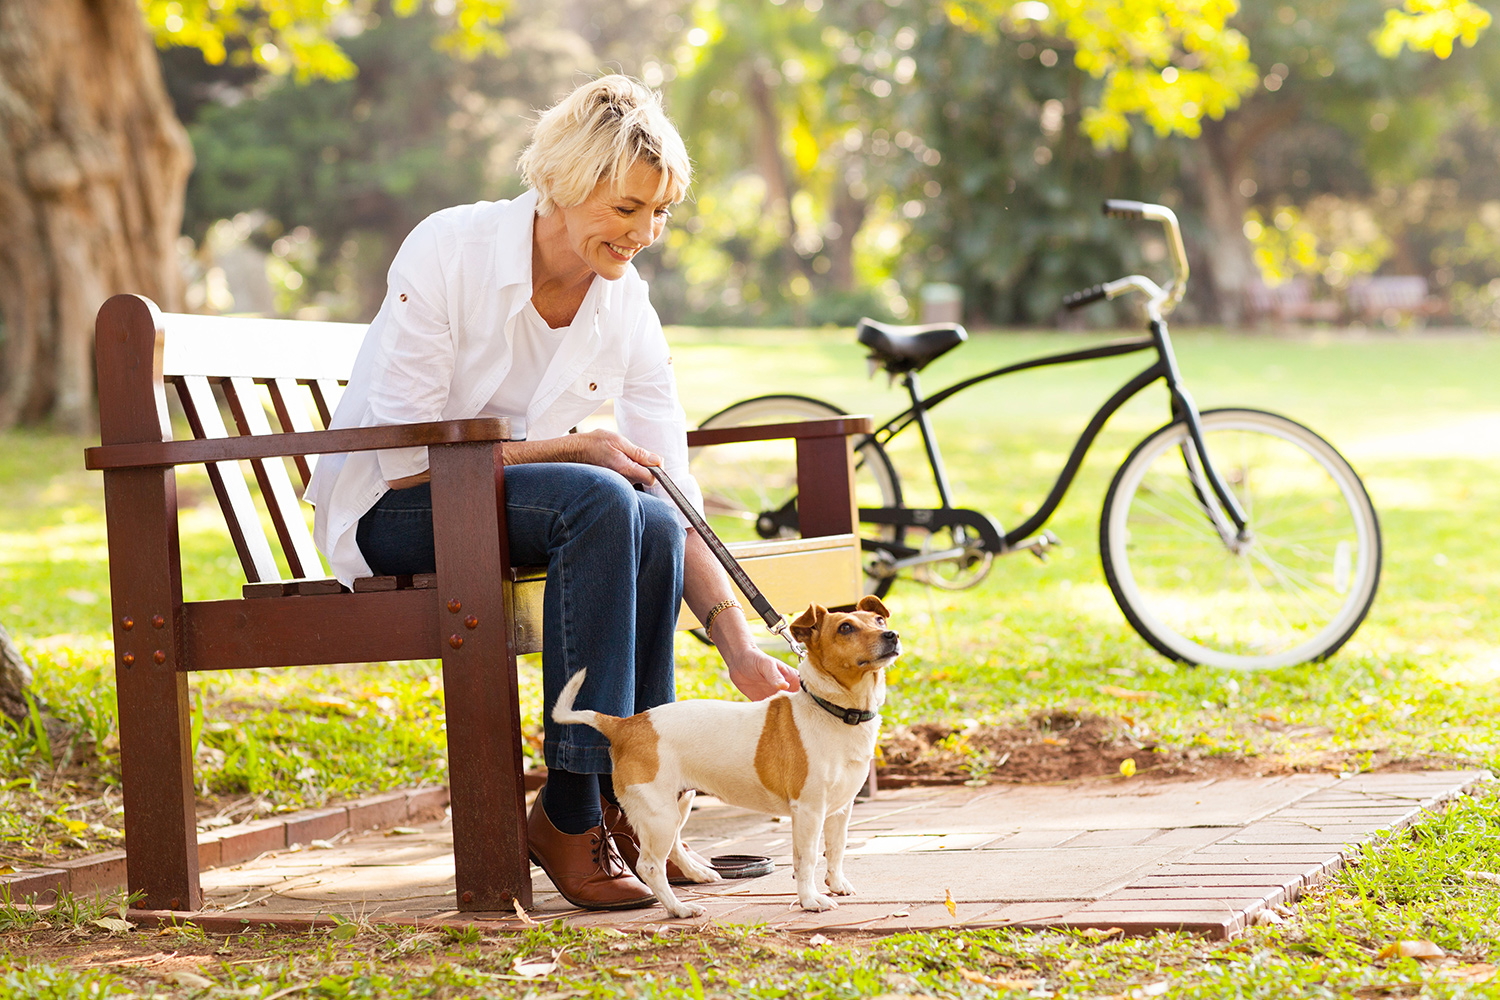


Image Classification identifies the primary object or scene in an image.

Please upload an image for classification:


Saving demo-pic-2.jpg to demo-pic-2.jpg

Loading image: demo-pic-2.jpg


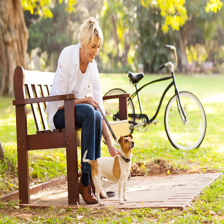

[transformers] No model was supplied, defaulted to google/vit-base-patch16-224 and revision 3f49326.
Using a pipeline without specifying a model name and revision in production is not recommended.


Initializing image classification pipeline...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Running classification...

--- Classification Results ---
Label: basenji, Score: 31.86%
Label: Chihuahua, Score: 11.63%
Label: toy terrier, Score: 5.97%
Label: whippet, Score: 4.62%
Label: Ibizan hound, Ibizan Podenco, Score: 3.61%


In [23]:
import os
from google.colab import files
from PIL import Image

# Allow user to upload an image
print("Please upload an image for classification:")
uploaded = files.upload()

if uploaded:
    file_path = list(uploaded.keys())[0]
    print(f"\nLoading image: {file_path}")

    # Open the uploaded image
    image = Image.open(file_path).convert("RGB")
    display(image.resize((224, 224)))

    # Run image classification
    print("Initializing image classification pipeline...")
    image_classification = pipeline("image-classification")

    print("Running classification...")
    result = image_classification(image)

    print("\n--- Classification Results ---")
    for pred in result:
        print(f"Label: {pred['label']}, Score: {pred['score']:.2%}")

    # Clean up uploaded file
    os.remove(file_path)
else:
    print("No image was uploaded. Please run the cell again to upload an image.")

### 7. Image Segmentation


Image Segmentation goes a step further by dividing the image into regions and labeling every pixel, allowing you to outline the exact shapes of objects.

Please upload an image for segmentation:


[transformers] No model was supplied, defaulted to facebook/detr-resnet-50-panoptic and revision d53b52a.
Using a pipeline without specifying a model name and revision in production is not recommended.


Saving demo-pic-2.jpg to demo-pic-2.jpg

Loading image: demo-pic-2.jpg
Initializing image segmentation pipeline...


config.json:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  172MB            

...

Loading weights:   0%|          | 0/562 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

Running segmentation (this might take a few moments)...


[transformers] `label_ids_to_fuse` unset. No instance will be fused.



Detected 6 segment regions:
Region 1: Label = bench, Score = 99.89%


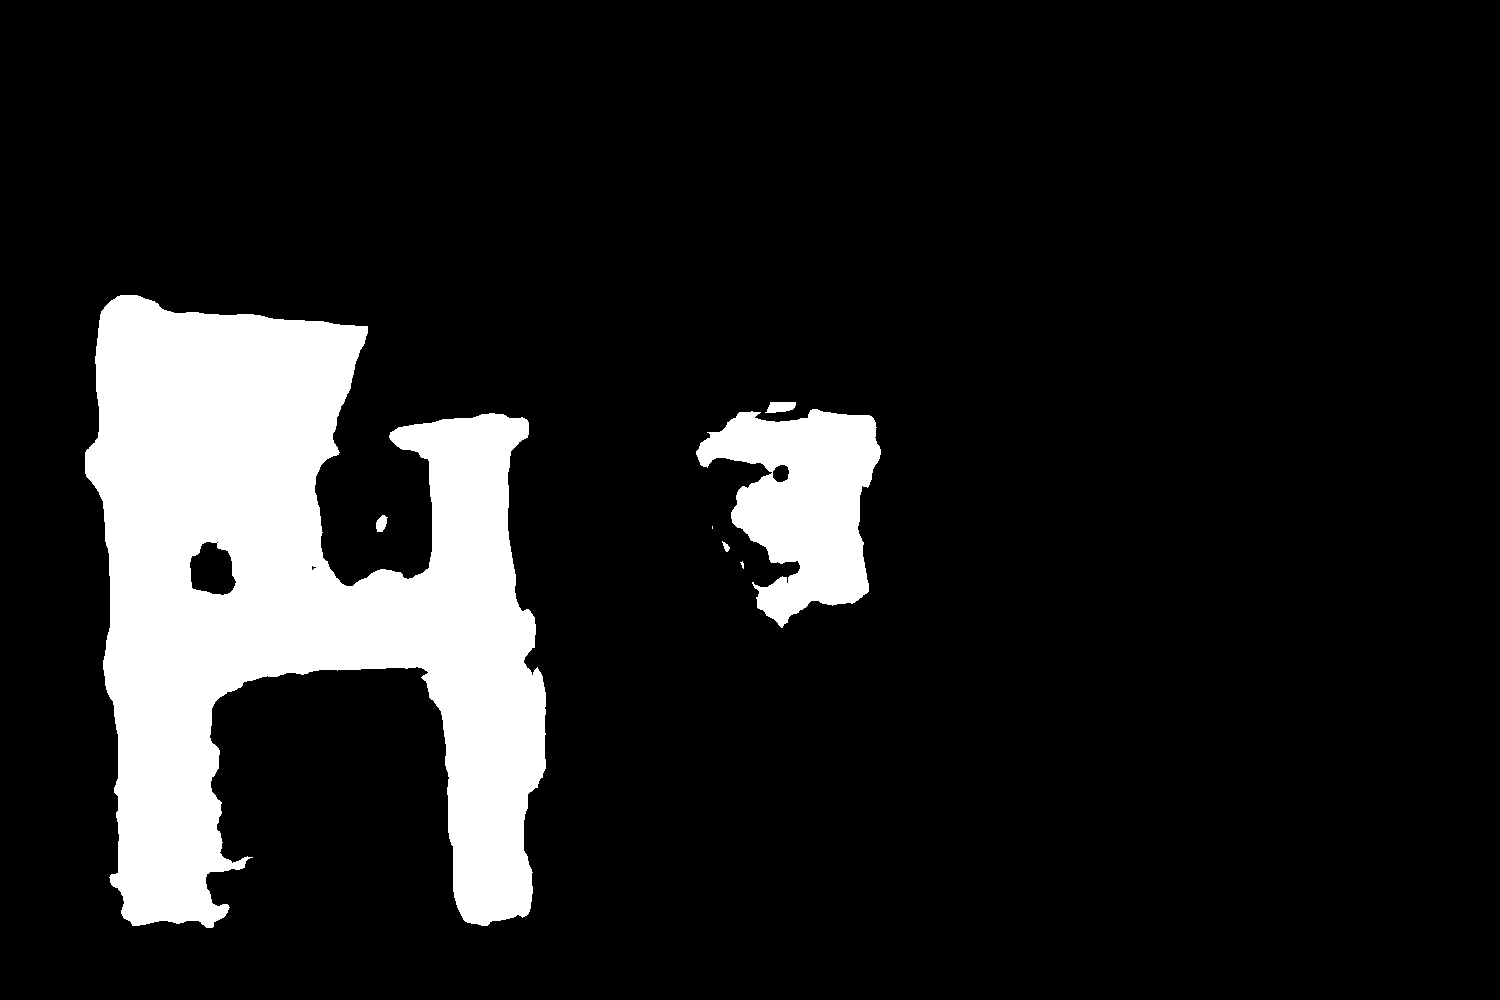

Region 2: Label = bicycle, Score = 99.92%


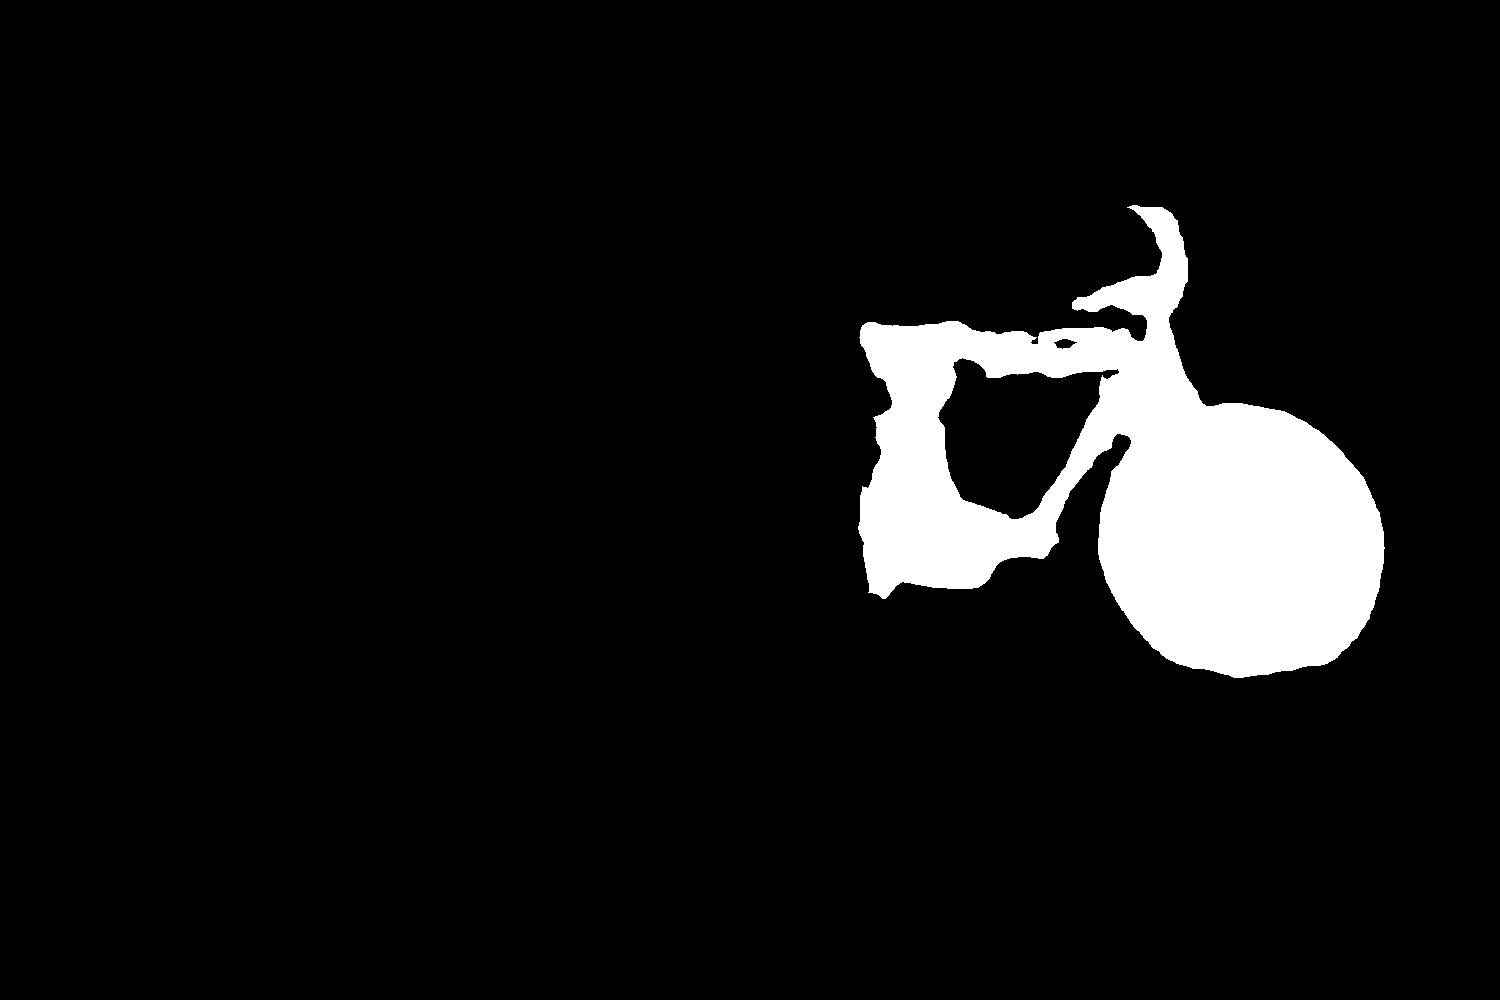

Region 3: Label = dog, Score = 99.99%


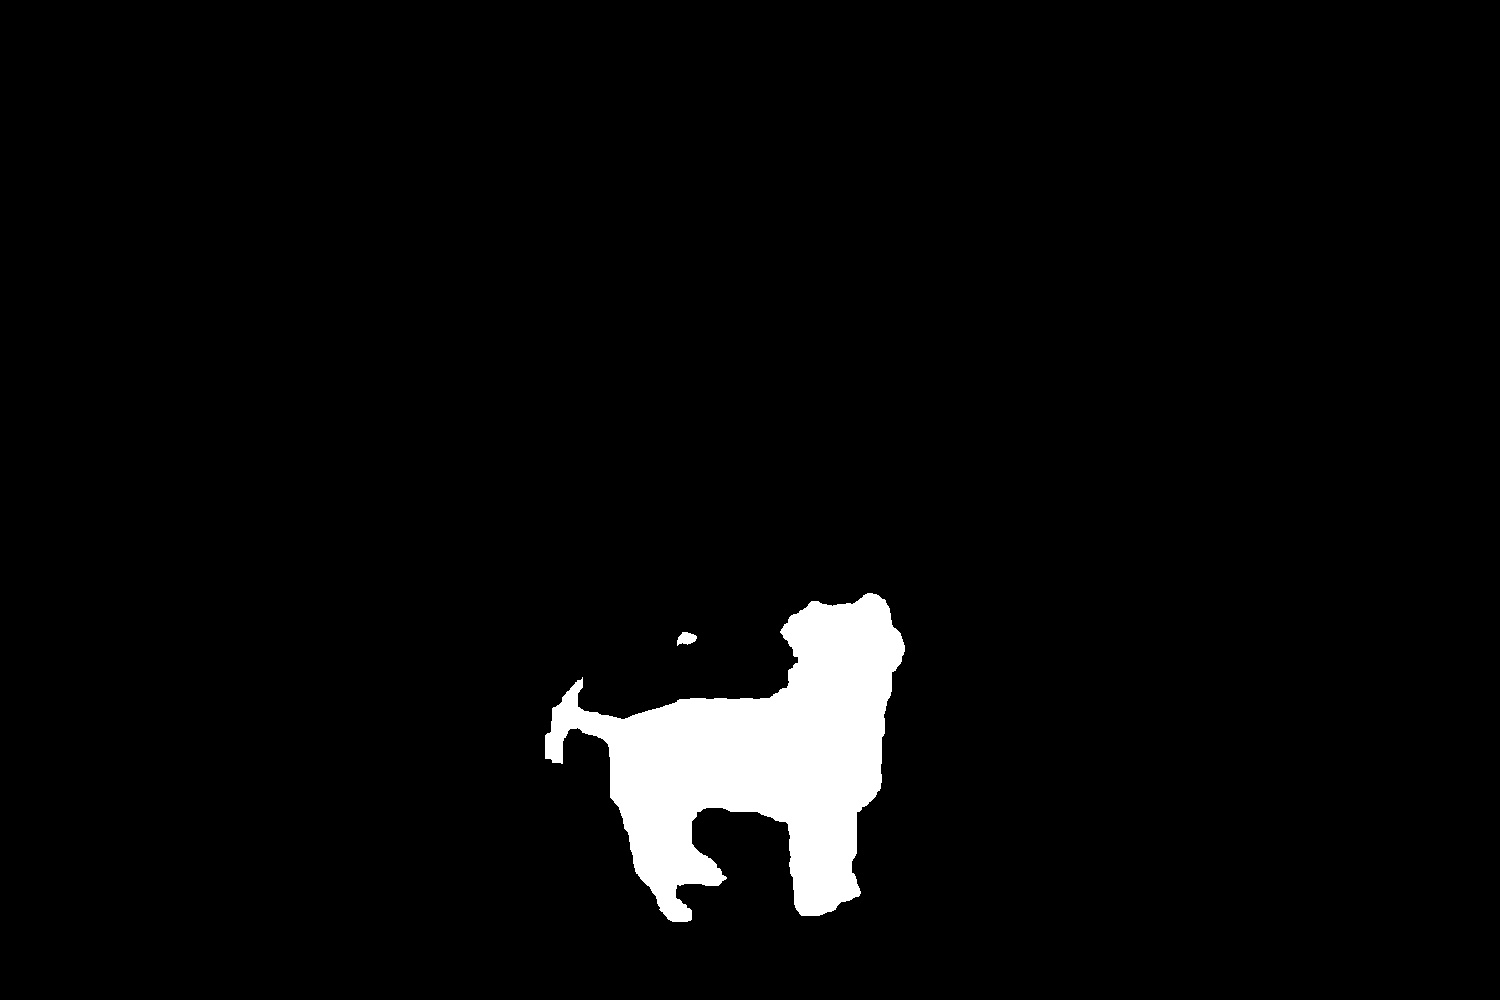

Region 4: Label = LABEL_184, Score = 98.83%


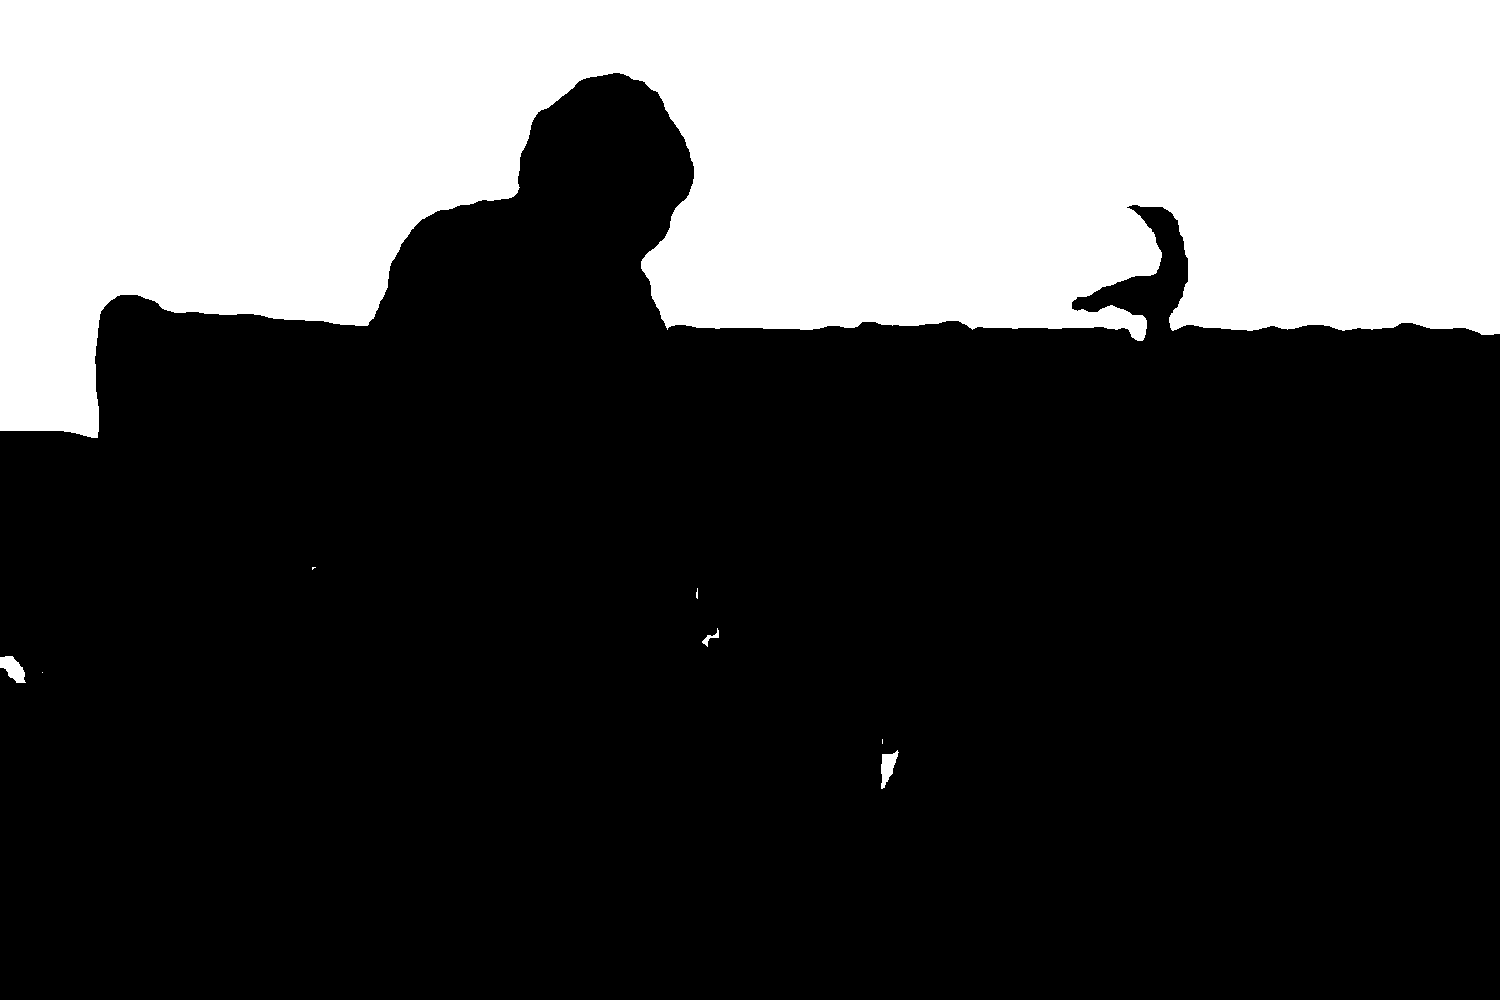

Region 5: Label = person, Score = 99.93%


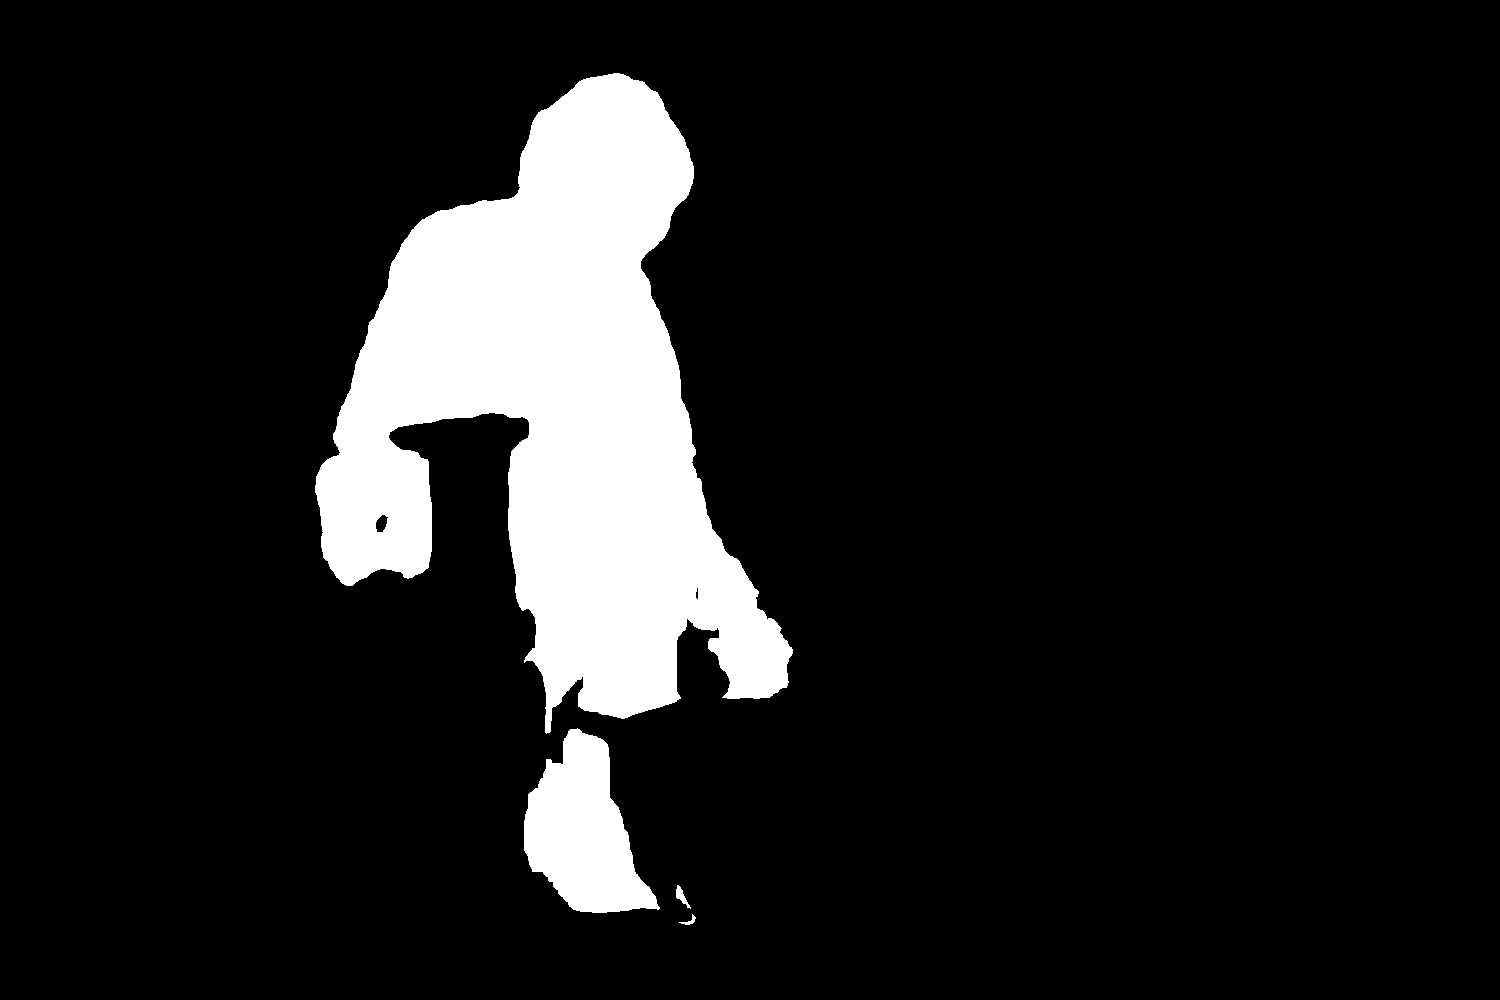

Region 6: Label = LABEL_193, Score = 95.34%


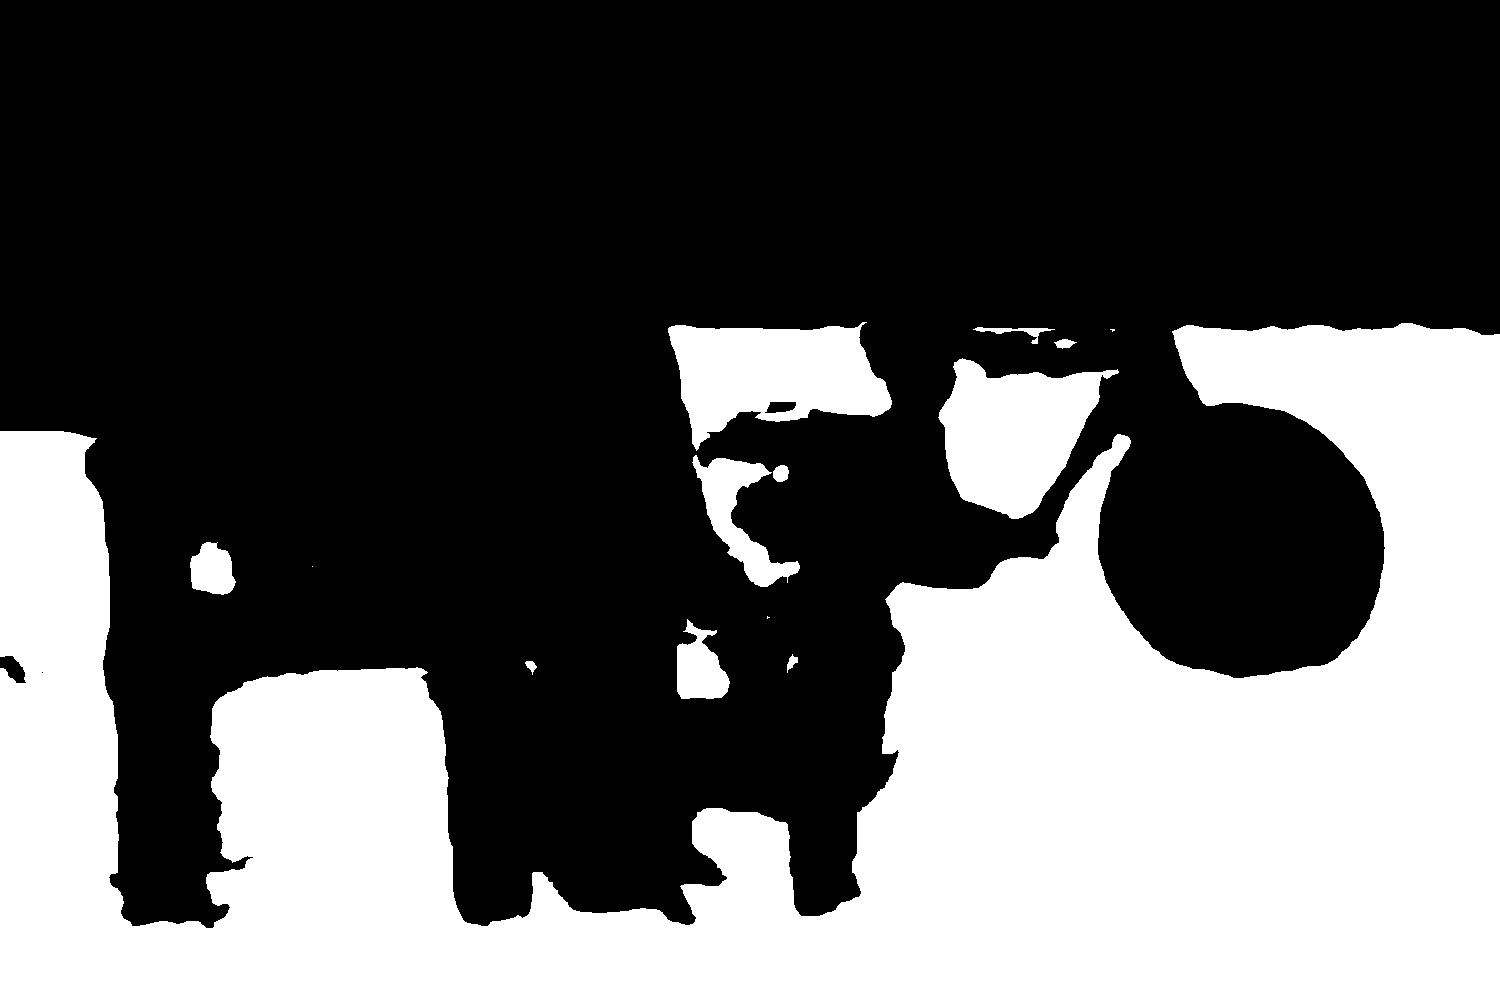

In [2]:
import os
import numpy as np
from google.colab import files
from PIL import Image

# Allow user to upload an image
print("Please upload an image for segmentation:")
uploaded = files.upload()

if uploaded:
    file_path = list(uploaded.keys())[0]
    print(f"\nLoading image: {file_path}")

    # Open the uploaded image
    image = Image.open(file_path).convert("RGB")

    # Run image segmentation
    print("Initializing image segmentation pipeline...")
    image_segmentation = pipeline("image-segmentation")

    print("Running segmentation (this might take a few moments)...")
    results = image_segmentation(image)

    # Display the segmented mask regions visually
    print(f"\nDetected {len(results)} segment regions:")
    for i, res in enumerate(results):
        print(f"Region {i+1}: Label = {res['label']}, Score = {res['score']:.2%}")
        mask = res["mask"]
        display(mask)

    # Clean up uploaded file
    os.remove(file_path)
else:
    print("No image was uploaded. Please run the cell again to upload an image.")

### 8. Object Detection

Object Detection identifies and locates multiple objects within an image. It draws bounding boxes around detected entities and classifies each box into a target class.

Please upload an image file (e.g., .jpg, .png, .jpeg):


[transformers] No model was supplied, defaulted to facebook/detr-resnet-50 and revision 1d5f47b.
Using a pipeline without specifying a model name and revision in production is not recommended.


Saving demo-pic-2.jpg to demo-pic-2.jpg

Loading image: demo-pic-2.jpg
Initializing object detection pipeline...


config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

Running detection...

--- Detection Result Visualized ---


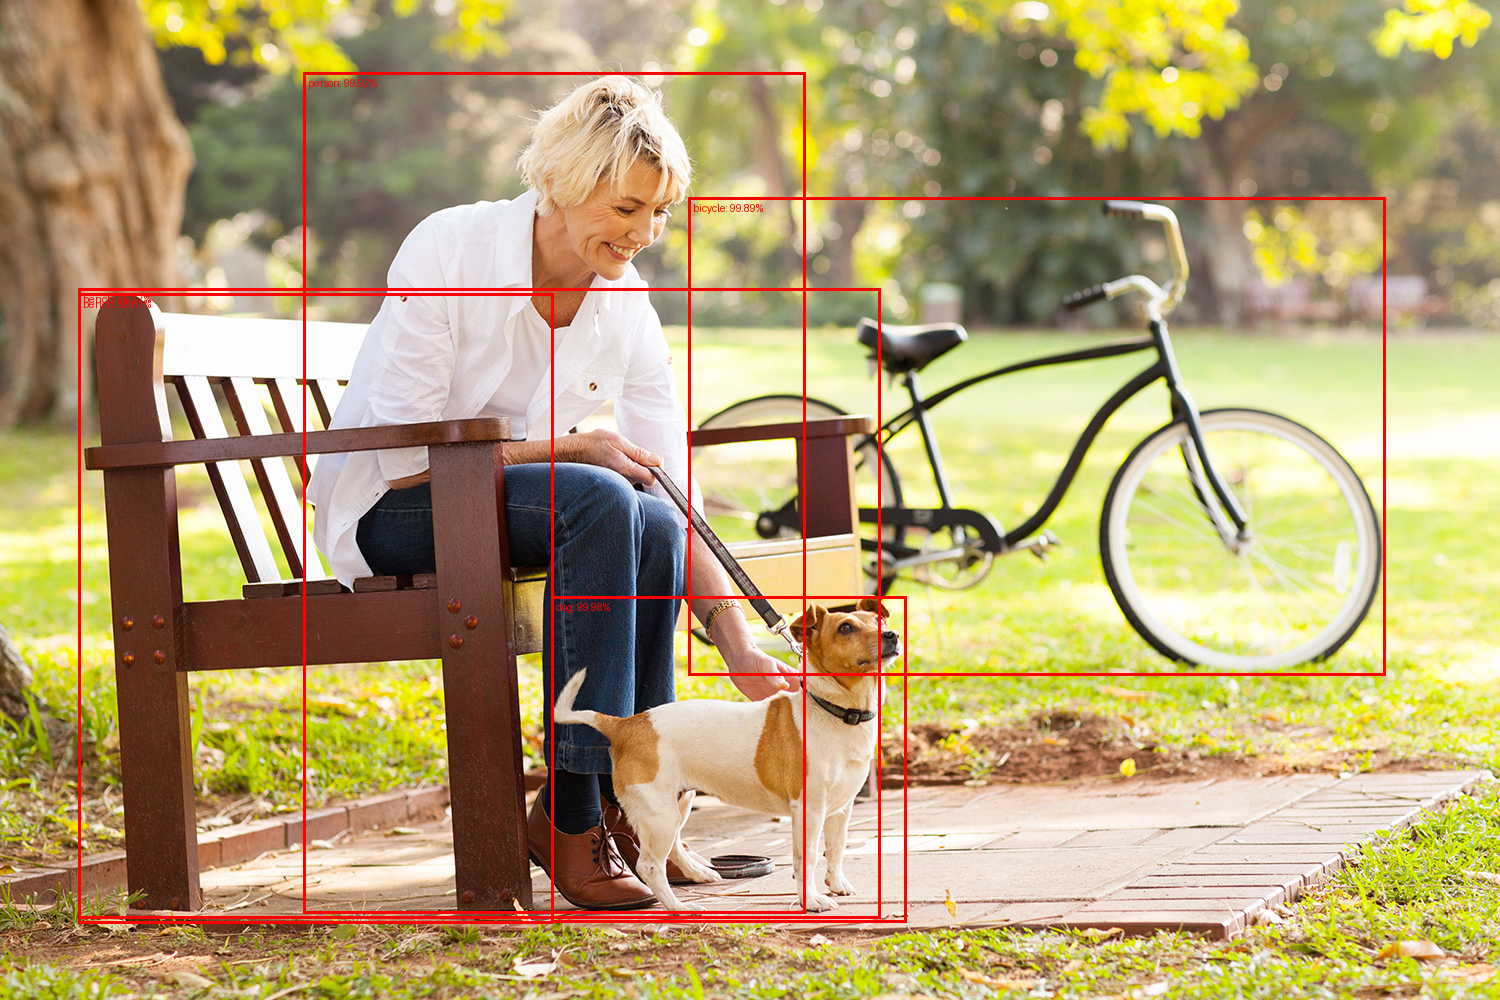

In [3]:
import os
from google.colab import files
from PIL import Image, ImageDraw, ImageFont

# 1. Allow user to upload an image
print("Please upload an image file (e.g., .jpg, .png, .jpeg):")
uploaded = files.upload()

if uploaded:
    file_path = list(uploaded.keys())[0]
    print(f"\nLoading image: {file_path}")

    # Open the uploaded image
    image = Image.open(file_path).convert("RGB")

    # 2. Load the object detection pipeline
    print("Initializing object detection pipeline...")
    detector = pipeline("object-detection")

    # 3. Detect objects
    print("Running detection...")
    detections = detector(image)

    # 4. Draw bounding boxes on the image
    draw = ImageDraw.Draw(image)

    # Optional: Load a default font
    try:
        font = ImageFont.load_default()
    except Exception:
        font = None

    for detection in detections:
        box = detection["box"]
        label = detection["label"]
        score = detection["score"]

        # Bounding box coordinates
        xmin, ymin, xmax, ymax = box["xmin"], box["ymin"], box["xmax"], box["ymax"]

        # Draw the rectangle box
        draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)

        # Draw text label
        text = f"{label}: {score:.2%}"
        draw.text((xmin + 5, ymin + 5), text, fill="red", font=font)

    # 5. Display the result
    print("\n--- Detection Result Visualized ---")
    display(image)

    # Clean up uploaded file
    os.remove(file_path)
else:
    print("No image was uploaded. Please run the cell again to upload an image.")

### 9. Question Answering (Text-based)


Extractive Question Answering involves finding the exact span of text within a given context document that directly answers a user's question.

In [20]:
import pandas as pd

questions = [
    {
        "id": 1,
        "category": "General AI",
        "question": "What is the difference between Strong AI (General) and Weak AI (Narrow)?",
        "answer": "Strong AI possesses human-like cognitive abilities to solve any intellectual task, while Weak AI is designed and trained for a specific task."
    },
    {
        "id": 2,
        "category": "Machine Learning",
        "question": "Explain the fundamental difference between supervised, unsupervised, and reinforcement learning.",
        "answer": "Supervised learning uses labeled training data; unsupervised learning finds hidden patterns in unlabeled data; and reinforcement learning trains an agent to maximize cumulative rewards through actions in an environment."
    },
    {
        "id": 3,
        "category": "Deep Learning",
        "question": "What is a neural network, and how do weights and biases function within it?",
        "answer": "A neural network is a computational model inspired by the brain where weights determine signal strength and biases shift activation functions."
    },
    {
        "id": 4,
        "category": "Deep Learning",
        "question": "What is backpropagation, and how does it utilize gradient descent to train models?",
        "answer": "Backpropagation computes gradients of the loss function and updates network parameters using gradient descent."
    },
    {
        "id": 5,
        "category": "Machine Learning",
        "question": "What are overfitting and underfitting, and how can they be prevented?",
        "answer": "Overfitting occurs when a model learns training data noise, while underfitting happens when it is too simple. They can be prevented using techniques like cross-validation."
    },
    {
        "id": 6,
        "category": "Natural Language Processing",
        "question": "What is the Transformer architecture, and why is the self-attention mechanism so important?",
        "answer": "The Transformer architecture processes sequences in parallel utilizing a self-attention mechanism to capture contextual relationships between words."
    },
    {
        "id": 7,
        "category": "Generative AI",
        "question": "How do Generative Adversarial Networks (GANs) work, and what are their primary components?",
        "answer": "GANs consist of a generator and a discriminator competing against each other to create realistic synthetic data."
    },
    {
        "id": 8,
        "category": "Computer Vision",
        "question": "How does a Convolutional Neural Network (CNN) process spatial hierarchies in images?",
        "answer": "CNNs process spatial hierarchies in images using learnable visual filters."
    },
    {
        "id": 9,
        "category": "Natural Language Processing",
        "question": "What is tokenization in NLP, and why is it a necessary preprocessing step?",
        "answer": "Tokenization breaks raw text down into smaller chunks or tokens to prepare them for sequence processing."
    },
    {
        "id": 10,
        "category": "Machine Learning",
        "question": "Explain the concept of Bias-Variance Tradeoff.",
        "answer": "The Bias-Variance Tradeoff balances model bias (simplifying assumptions) and variance (sensitivity to training data fluctuations) to minimize total prediction error."
    },
    {
        "id": 11,
        "category": "Reinforcement Learning",
        "question": "What are the main components of a Reinforcement Learning system (agent, environment, state, action, reward)?",
        "answer": "The system consists of an agent interacting with an environment by observing states, performing actions, and receiving rewards."
    },
    {
        "id": 12,
        "category": "AI Ethics",
        "question": "What is algorithmic bias, and how can it impact automated decision-making systems?",
        "answer": "Algorithmic bias occurs when models reproduce historical human prejudices, negatively impacting fairness in automated decisions."
    },
    {
        "id": 13,
        "category": "Deep Learning",
        "question": "Why do we use activation functions like ReLU, Sigmoid, or Softmax in neural networks?",
        "answer": "They introduce non-linearities into the network, allowing it to learn and represent complex data relationships."
    },
    {
        "id": 14,
        "category": "Machine Learning",
        "question": "What is the purpose of cross-validation in evaluating machine learning models?",
        "answer": "Cross-validation partitions data to ensure robust model evaluation and avoid overfitting during training."
    },
    {
        "id": 15,
        "category": "Generative AI",
        "question": "What are Large Language Models (LLMs), and what does the process of fine-tuning involve?",
        "answer": "LLMs are massive neural networks trained on textual data; fine-tuning involves adapting them to specialized downstream tasks using target datasets."
    },
    {
        "id": 16,
        "category": "Natural Language Processing",
        "question": "How do word embeddings (like Word2Vec or GloVe) capture semantic relationships between words?",
        "answer": "They map words to high-dimensional continuous vector spaces where geometric proximity corresponds to semantic similarity."
    },
    {
        "id": 17,
        "category": "Deep Learning",
        "question": "What is transfer learning, and what are its practical advantages?",
        "answer": "Transfer learning applies knowledge gained from solving one problem to a different but related task, saving training computation and data."
    },
    {
        "id": 18,
        "category": "Computer Vision",
        "question": "What is the difference between object detection and image segmentation?",
        "answer": "Object detection identifies boundaries via boxes, while image segmentation maps and labels every individual pixel."
    },
    {
        "id": 19,
        "category": "AI Ethics",
        "question": "What is Explainable AI (XAI), and why is model interpretability crucial in high-stakes fields?",
        "answer": "XAI provides mechanisms to make machine decisions transparent and comprehensible to human users."
    },
    {
        "id": 20,
        "category": "General AI",
        "question": "What is the Turing Test, and what are its limitations in determining true machine intelligence?",
        "answer": "The Turing Test assesses behavioral imitation rather than deep semantic comprehension or genuine understanding."
    }
]

# Display the structured list of questions with their added ground-truth answers
df_questions = pd.DataFrame(questions).set_index("id")
display(df_questions)


,category,question,answer
id,,,
1,General AI,What is the difference between Strong AI (Gene...,Strong AI possesses human-like cognitive abili...
2,Machine Learning,Explain the fundamental difference between sup...,Supervised learning uses labeled training data...
3,Deep Learning,"What is a neural network, and how do weights a...",A neural network is a computational model insp...
4,Deep Learning,"What is backpropagation, and how does it utili...",Backpropagation computes gradients of the loss...
5,Machine Learning,"What are overfitting and underfitting, and how...",Overfitting occurs when a model learns trainin...
6,Natural Language Processing,"What is the Transformer architecture, and why ...",The Transformer architecture processes sequenc...
7,Generative AI,How do Generative Adversarial Networks (GANs) ...,GANs consist of a generator and a discriminato...
8,Computer Vision,How does a Convolutional Neural Network (CNN) ...,CNNs process spatial hierarchies in images usi...
9,Natural Language Processing,"What is tokenization in NLP, and why is it a n...",Tokenization breaks raw text down into smaller...


In [21]:
from PIL import Image, ImageDraw

# 1. Define a clean knowledge context
ai_knowledge_context = """
Artificial Intelligence (AI) can be divided into Strong AI (General AI), which possesses human-like cognitive abilities to solve any intellectual task, and Weak AI (Narrow AI), which is designed and trained for a specific task like translation or chess.
Machine Learning (ML) relies on different paradigms: supervised learning uses labeled training data; unsupervised learning finds hidden patterns in unlabeled data; and reinforcement learning trains an agent to maximize cumulative rewards through actions in an environment (comprising an agent, environment, state, action, and reward).
A neural network is a computational model inspired by the human brain. It functions using interconnected nodes where weights determine the strength of the signal and biases shift the activation function. Training these networks involves backpropagation, which computes gradients of the loss function and updates parameters using gradient descent.
Models can face generalization issues: overfitting occurs when a model learns training data noise too well, while underfitting happens when it is too simple. This is related to the Bias-Variance Tradeoff, where bias represents simplifying assumptions, and variance represents sensitivity to training data fluctuations. Cross-validation is commonly used to evaluate model generalization performance.
In Natural Language Processing (NLP), text must first undergo tokenization to break characters into smaller pieces or tokens. Word embeddings like Word2Vec or GloVe represent words as vectors capturing semantic relations. The Transformer architecture revolutionized NLP by introducing the self-attention mechanism to process entire sequences in parallel. Large Language Models (LLMs) are massive transformers that can be fine-tuned on task-specific datasets.
For Computer Vision, Convolutional Neural Networks (CNNs) process spatial hierarchies using filters. While object detection draws bounding boxes around items, image segmentation classifies every individual pixel. Generative Adversarial Networks (GANs) consist of a generator and a discriminator competing to create realistic images.
AI Ethics covers algorithmic bias, where models reproduce historical or human prejudices in decision-making, and Explainable AI (XAI), which ensures machine outputs can be understood and trusted by human experts. Finally, the Turing Test is a historical benchmark of machine intelligence testing whether a computer can mimic human conversation, though it is limited because it tests behavior rather than genuine understanding.
"""

# 2. Select a question
index = int(input("Choose question ID (1 to 20): "))
selected_question_dict = questions[index - 1]
print(f"Selected Question: {selected_question_dict['question']}\n")

# 3. Create an image containing our context text to feed into the document-question-answering pipeline
img = Image.new("RGB", (800, 1000), color=(255, 255, 255))
draw = ImageDraw.Draw(img)

# Draw our text context on the image
y_text = 20
for line in ai_knowledge_context.split('\n'):
    words = line.split()
    lines = []
    current_line = ""
    for word in words:
        test_line = current_line + " " + word if current_line else word
        if len(test_line) < 90:
            current_line = test_line
        else:
            lines.append(current_line)
            current_line = word
    if current_line:
        lines.append(current_line)

    for l in lines:
        draw.text((20, y_text), l, fill=(0, 0, 0))
        y_text += 18
    y_text += 10

# 4. Load the document-question-answering pipeline
doc_qa = pipeline("document-question-answering", model="naver-clova-ix/donut-base-finetuned-docvqa")

# 5. Get the answer using the document image
answer_result = doc_qa(
    image=img,
    question=selected_question_dict["question"]
)

predicted_answer = answer_result[0]['answer'] if isinstance(answer_result, list) else answer_result['answer']

print(f"Predicted Answer: {predicted_answer}")
print(f"Ground-truth Answer: {selected_question_dict['answer']}")

Choose question ID (1 to 20): 7
Selected Question: How do Generative Adversarial Networks (GANs) work, and what are their primary components?



Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Predicted Answer: gans
Ground-truth Answer: GANs consist of a generator and a discriminator competing against each other to create realistic synthetic data.


### 10. Recap

Here is a comprehensive summary of the different Hugging Face pipelines demonstrated in this notebook, highlighting their modalities, typical inputs, and primary use cases:

| Section | Pipeline Task | Input Modality | Key Outputs | Real-World Application |
| :--- | :--- | :--- | :--- | :--- |
| **1** | `text-classification` | Text (e.g., reviews) | Label (e.g., POSITIVE) & Score | Sentiment analysis, spam detection |
| **2** | `text-generation` | Text prompt | Continued text continuation | Creative writing, conversational AI |
| **3** | `text-to-speech` | Text string | Spoken audio waveform | Audiobooks, accessibility readers |
| **4** | `audio-classification` | Audio array | Class labels & confidence scores | Keyword spotting, music genre tagging |
| **5** | `automatic-speech-recognition` | Audio waveform | Transcribed textual text | Automated subtitling, voice command decoding |
| **6** | `image-classification` | Image | Predicted scene/object category | Photo tagging, product categorization |
| **7** | `image-segmentation` | Image | Class masks outlining specific shapes | Autonomous driving, medical imaging |
| **8** | `object-detection` | Image | Bounding box coordinates & class labels | Surveillance, autonomous vehicle detection |
| **9** | `document-question-answering` | Image + Text Question | Textual answer span | Invoice parsing, digitized form data extraction |